Part A — Dataset and LBP

In [356]:
#Imports
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import cv2
from skimage.feature import local_binary_pattern

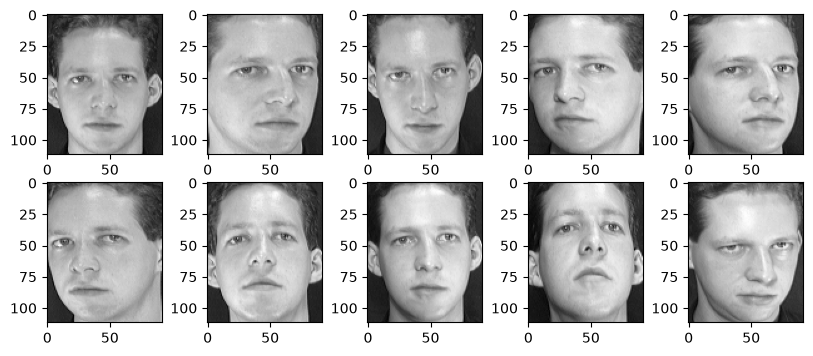

In [357]:
#Read 10 images 
subject="s1"
n=10

plt.figure(figsize=(10,4))

for i in range(n):
    image_path=Path('att_faces')/subject/f"{i+1}.pgm"
    image=cv2.imread(str(image_path),0)    #0 for gray image

    plt.subplot(2,5,i+1)
    plt.imshow(image,cmap='gray')


In [358]:
#Image Path
subject="s1"
image_name="1.pgm"
image_path=Path('att_faces')/subject/image_name

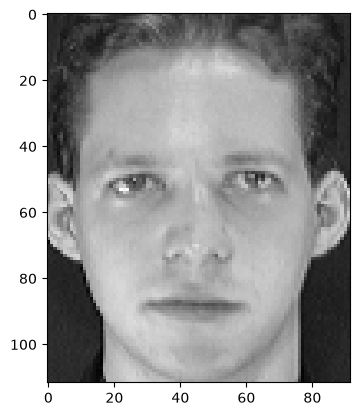

In [359]:
image=cv2.imread(image_path)
gray_image=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
plt.imshow(gray_image,cmap='gray')


In [360]:
print("Shape of the Matrix : ",gray_image.shape)
print("\nImage as Matrix : ")
print(gray_image)

Shape of the Matrix :  (112, 92)

Image as Matrix : 
[[48 49 45 ... 56 56 54]
 [45 52 39 ... 52 50 51]
 [45 50 42 ... 48 53 50]
 ...
 [50 48 50 ... 45 46 46]
 [45 54 49 ... 46 47 47]
 [51 51 51 ... 47 46 46]]


[[129.  64.  49. ...   1.  16.  16.]
 [199.   0. 255. ...  30. 255.  44.]
 [199.   4. 251. ... 159.   0. 124.]
 ...
 [128. 245.  32. ... 239. 229. 120.]
 [199.   0. 124. ... 195.   1.  16.]
 [  3.  21.  24. ...   0.  31.  28.]]

LBP Matrix Size :  (112, 92)


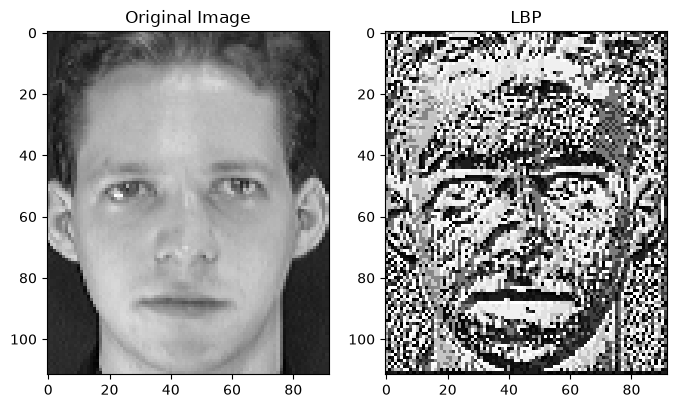

In [361]:
#LBP Map
neighbors=8
r=1
lbp_map=local_binary_pattern(gray_image,neighbors,r,method='default')
print(lbp_map)
plt.figure(figsize=(8,10))
plt.subplot(1,2,1)
plt.title("Original Image")
plt.imshow(gray_image,cmap='gray')
plt.subplot(1,2,2)
plt.title("LBP")
plt.imshow(lbp_map,cmap='gray')

print("\nLBP Matrix Size : ",lbp_map.shape)

Patch : 
 [[181 171 167]
 [181 174 168]
 [182 177 173]]
Patch LBP : 
 [[ 64. 112. 112.]
 [ 68. 120. 120.]
 [  0.  24.  24.]]


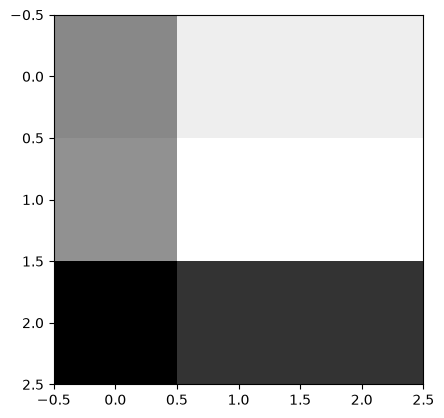

In [362]:
# Consider a small 3*3 patch around the pixel 50, 45. Compute the LBP, and display the
# LBP feature. Compute the histogram of LBP

patch=gray_image[50-1:50+2,45-1:45+2]
patch_lbp=local_binary_pattern(patch,neighbors,r,method= 'default')
plt.imshow(patch_lbp,cmap='gray')
print("Patch : \n",patch)
print("Patch LBP : \n",patch_lbp)

In [363]:
x=50
y=45
x_min=x-1
x_max=x+2
y_min=y-1
y_max=y+2

#center
n=3-1
patch=gray_image[x_min:x_max,y_min:y_max]

print("Original Patch : \n",patch)

c=patch[n//2][n//2]
print("Center : ",c)

for i in range(n+1):
    for j in range(n+1):
        if patch[i][j]<=c:
            patch[i][j]=0
        else:
            patch[i][j]=1

print("Final Patch : \n",patch)

k=0
#row1
sum=0
p=0
for i in range(3):
    sum=sum+patch[0][i]*2**p
    p=p+1
#row2 right
sum=sum+patch[1][2]*2**p
p=p+1

for i in range(2,-1,-1):
    sum=sum+patch[2][i]*2**p
    p=p+1

#row2 left
sum=sum+patch[1][0]*2**p
p=p+1


print("LBP : ",sum)


Original Patch : 
 [[181 171 167]
 [181 174 168]
 [182 177 173]]
Center :  174
Final Patch : 
 [[1 0 0]
 [1 0 0]
 [1 1 0]]
LBP :  225


In [364]:
def my_lbp(x,y):
    x_min=x-1
    x_max=x+2
    y_min=y-1
    y_max=y+2

    #center
    n=3-1
    patch=gray_image[x_min:x_max,y_min:y_max].copy()

    c=patch[n//2][n//2]

    for i in range(n+1):
        for j in range(n+1):
            if patch[i][j]<=c:
                patch[i][j]=0
            else:
                patch[i][j]=1

    k=0
    #row1
    sum=0
    p=0
    for i in range(3):
        sum=sum+patch[0][i]*2**p
        p=p+1
    #row2 right
    sum=sum+patch[1][2]*2**p
    p=p+1

    for i in range(2,-1,-1):
        sum=sum+patch[2][i]*2**p
        p=p+1

    #row2 left
    sum=sum+patch[1][0]*2**p
    p=p+1

    return sum


In [365]:
a,b=gray_image.shape
m,n=a-3+1,b-3+1   #size of LBP array
lbp_arr = np.zeros((m, n))
i,j=0,0
for x in range(1,a-1,1):
    for y in range(1,b-1,1):
        lbp_arr[i][j]=my_lbp(x,y)
        j=j+1
    i=i+1
    j=0
lbp_arr

array([[  0., 255.,  62., ...,   5., 150., 175.],
       [  2., 253.,   4., ...,   6., 159.,   0.],
       [154.,  21.,  62., ...,   7.,  31.,  42.],
       ...,
       [  0., 255.,   0., ...,   2., 157.,   4.],
       [186.,  69., 222., ..., 254.,  61.,  50.],
       [  0., 226., 221., ..., 153.,  40.,   0.]], shape=(110, 90))

<BarContainer object of 256 artists>

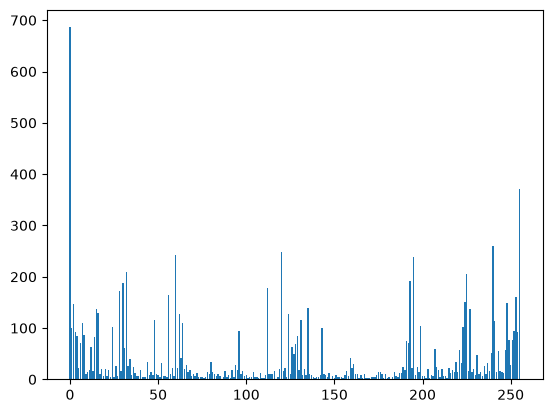

In [366]:
lbp_hist=np.histogram(
    lbp_arr.ravel(),
    bins=np.arange(257),
    range=(0,256)
)[0]
plt.bar(np.arange(256), lbp_hist)

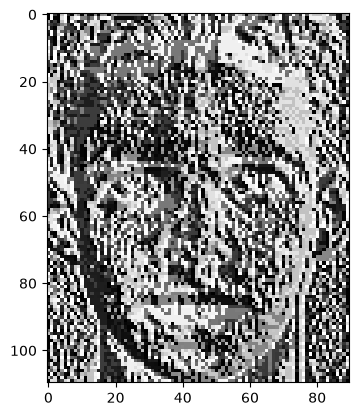

In [367]:
plt.imshow(lbp_arr,cmap='gray')

Part B — HOG

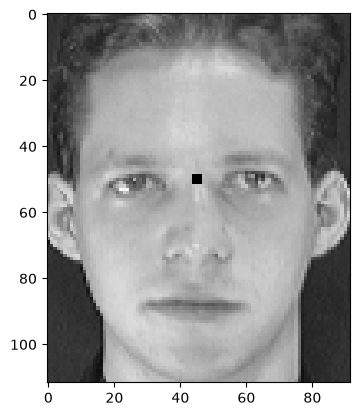

In [368]:
# Display the face and apply hog() using 9 orientations, 8×8 cells and 2×2 blocks.
# Show the HOG visualization and feature-vector length.

plt.imshow(gray_image,cmap='gray')

(np.float64(-0.5), np.float64(91.5), np.float64(111.5), np.float64(-0.5))

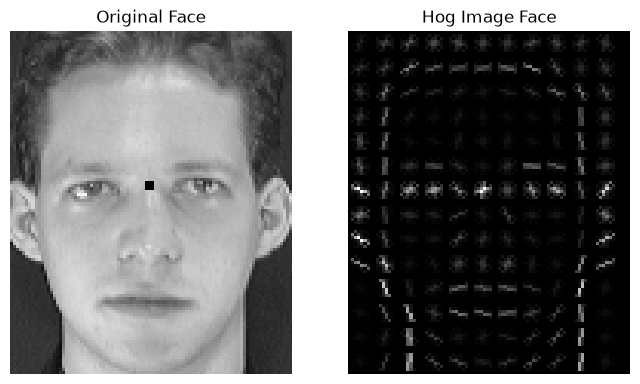

In [369]:
from skimage.feature import hog

features, hog_image=hog(gray_image,orientations=8,cells_per_block=(2,2),pixels_per_cell=(8,8),visualize=True)

plt.figure(figsize=(8,6))

plt.subplot(1,2,1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Face")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(hog_image, cmap="gray")
plt.title("Hog Image Face")
plt.axis("off")



In [370]:
# Highlight one 3×3 patch around an edge and display its values.

patch=hog_image[0:3,0:3]
print(patch)


[[0.         0.         0.        ]
 [0.         0.         0.76044679]
 [0.         0.0912753  0.        ]]


In [371]:
sx=np.array([[1,0,-1],[2,0,-2],[1,0,-1]])  #Flipping applied
sy=np.array([[1,2,1],[0,0,0],[-1,-2,-1]])  #Flipping applied


In [372]:
def my_gx(x,y):
    k,l=0,0
    sum=0
    for i in range(x-1,x+2,1):
        for j in range(y-1,y+2,1):
            sum=sum + (sx[k][l]) * gray_image[i][j]
            l=l+1;
        k=k+1
        l=0;

    return sum

def my_gy(x,y):
    k,l=0,0
    sum=0
    for i in range(x-1,x+2,1):
        for j in range(y-1,y+2,1):
            sum=sum + (sy[k][l]) * gray_image[i][j]
            l=l+1;
        k=k+1
        l=0;

    return sum

In [373]:
#Gx
a,b=gray_image.shape
m,n=a-3+1,b-3+1   #size of gradient array
gx=np.zeros((m, n))
i,j=0,0
for x in range(1,a-1,1):
    for y in range(1,b-1,1):
        gx[i][j]=my_gx(x,y)
        j=j+1
    i=i+1
    j=0
gx

array([[ 18.,  13., -47., ...,  -2.,  -1.,   2.],
       [ 14.,   3., -38., ..., -11.,  -8., -11.],
       [  6.,  -5., -16., ..., -30., -31., -25.],
       ...,
       [  4.,   2., -13., ...,  -4.,   0.,  -9.],
       [ -2.,  12.,  -6., ...,   3.,  -6.,  -3.],
       [ -8.,  24.,  -3., ...,   4.,  -8.,  -2.]], shape=(110, 90))

In [374]:
#Gy
a,b=gray_image.shape
m,n=a-3+1,b-3+1   #size of gradient array
gy=np.zeros((m, n))
i,j=0,0
for x in range(1,a-1,1):
    for y in range(1,b-1,1):
        gy[i][j]=my_gy(x,y)
        j=j+1
    i=i+1
    j=0
gy

array([[  4.,   1.,  -7., ...,  14.,  19.,  18.],
       [  0., -11.,  -4., ...,  49.,  28.,   9.],
       [  2.,  -3.,   4., ...,  48.,  27.,   9.],
       ...,
       [ -4.,  -2.,   3., ...,   4.,   0.,   3.],
       [-10.,  -8.,   4., ...,  -3.,   2.,  -1.],
       [ -8.,  -4.,  -1., ...,   2.,  -4.,  -2.]], shape=(110, 90))

In [375]:
#Final Gradient
a,b=gray_image.shape
m,n=a-3+1,b-3+1   #size of gradient array
g_final=np.zeros((m,n))
for i in range(m):
    for j in range(n):
        g_final[i][j]=np.sqrt((gx[i][j])**2 + (gy[i][j])**2)

g_final

array([[18.43908891, 13.03840481, 47.51841748, ..., 14.14213562,
        19.02629759, 18.11077028],
       [14.        , 11.40175425, 38.20994635, ..., 50.21951812,
        29.12043956, 14.2126704 ],
       [ 6.32455532,  5.83095189, 16.4924225 , ..., 56.60388679,
        41.10960958, 26.57066051],
       ...,
       [ 5.65685425,  2.82842712, 13.34166406, ...,  5.65685425,
         0.        ,  9.48683298],
       [10.19803903, 14.4222051 ,  7.21110255, ...,  4.24264069,
         6.32455532,  3.16227766],
       [11.3137085 , 24.33105012,  3.16227766, ...,  4.47213595,
         8.94427191,  2.82842712]], shape=(110, 90))

In [ ]:
# gradient direction

a,b=gray_image.shape
m,n=a-3+1,b-3+1   #size of gradient array
g_dir=np.zeros((m,n))
for i in range(m):
    for j in range(n):
        g_dir[i][j]=np.degrees(np.arctan((gy[i][j])/(gx[i][j])))% 180    # to convert angles between 0 and 180
g_dir

C:\Users\therm\AppData\Local\Temp\ipykernel_19936\227931350.py:8: RuntimeWarning: divide by zero encountered in scalar divide
  g_dir[i][j]=np.degrees(np.arctan((gy[i][j])/(gx[i][j])))% 180
C:\Users\therm\AppData\Local\Temp\ipykernel_19936\227931350.py:8: RuntimeWarning: invalid value encountered in scalar divide
  g_dir[i][j]=np.degrees(np.arctan((gy[i][j])/(gx[i][j])))% 180


array([[ 12.52880771,   4.39870535,   8.47114463, ...,  98.13010235,
         93.0127875 ,  83.65980825],
       [  0.        , 105.2551187 ,   6.00900596, ..., 102.6525565 ,
        105.9453959 , 140.71059314],
       [ 18.43494882,  30.96375653, 165.96375653, ..., 122.00538321,
        138.94518623, 160.20112365],
       ...,
       [135.        , 135.        , 167.00538321, ..., 135.        ,
                 nan, 161.56505118],
       [ 78.69006753, 146.30993247, 146.30993247, ..., 135.        ,
        161.56505118,  18.43494882],
       [ 45.        , 170.53767779,  18.43494882, ...,  26.56505118,
         26.56505118,  45.        ]], shape=(110, 90))

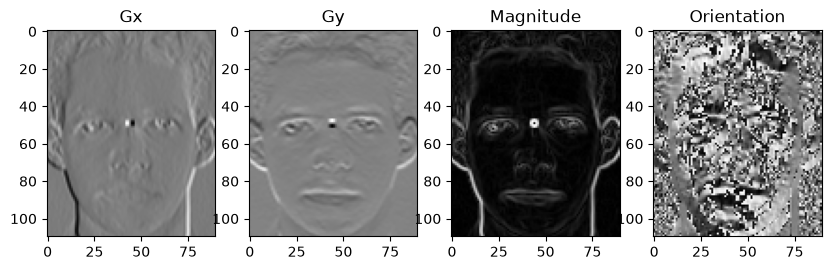

In [377]:
# Display horizontal gradients, vertical gradients, magnitude, and orientation images.

plt.figure(figsize=(10,8))

plt.subplot(1,4,1)
plt.title("Gx")
plt.imshow(gx,cmap="gray")

plt.subplot(1,4,2)
plt.title("Gy")
plt.imshow(gy,cmap="gray")

plt.subplot(1,4,3)
plt.title("Magnitude")
plt.imshow(g_final,cmap="gray")

plt.subplot(1,4,4)
plt.title("Orientation")
plt.imshow(g_dir,cmap="gray")

In [391]:
# Select an 8×8 cell. Write my_hog_cell() to calculate a 9-bin, magnitude-weighted orientation histogram.

def my_hog_cell(x_min,x_max,y_min,y_max,bin):
    o_hist=np.zeros(9)
    bin_length=180/bin
    for i in range(x_min,x_max):
        for j in range(y_min,y_max):
            k=int(g_dir[i][j]/bin_length)
            o_hist[k]=o_hist[k]+ g_final[i][j]
    return o_hist

print(my_hog_cell(0,8,0,8,9))

[464.94582267 737.27128382 259.38808526  21.55610153  75.16648189
  19.03616787  50.91168825 195.81648396 210.93892991]


[464.94582267 737.27128382 259.38808526  21.55610153  75.16648189
  19.03616787  50.91168825 195.81648396 210.93892991]


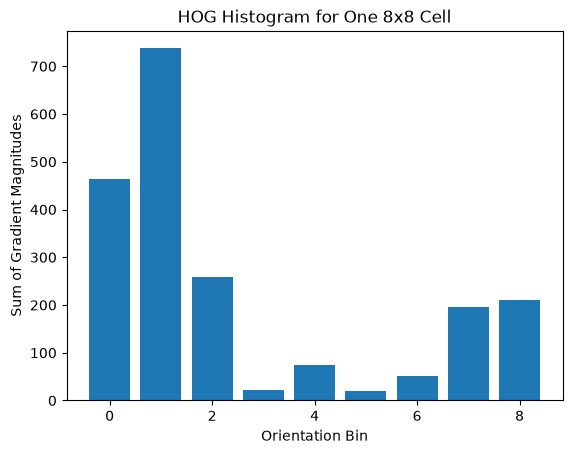

In [397]:
hist = my_hog_cell(0, 8, 0, 8, 9)
print(hist)

plt.bar(np.arange(9), hist)
plt.xlabel("Orientation Bin")
plt.ylabel("Sum of Gradient Magnitudes")
plt.title("HOG Histogram for One 8x8 Cell")
plt.show()

In [407]:
# Combine four adjacent cell histograms into a 36-value block and normalize it.
h1=my_hog_cell(0,8,0,8,9)
h2=my_hog_cell(8,16,0,8,9)
h3=my_hog_cell(0,8,8,16,9)
h4=my_hog_cell(8,16,8,16,9)

new=np.concatenate((h1,h2,h3,h4),axis=0)
sum=0
for i in range(0,36):
    sum=sum+(new[i]*new[i])
sum=np.sqrt(sum)

for i in range(0,36):
    new[i]=new[i]/sum

new


array([0.1659992 , 0.26322732, 0.0926091 , 0.00769616, 0.02683662,
       0.00679647, 0.01817696, 0.06991219, 0.07531134, 0.15100875,
       0.080279  , 0.08790145, 0.12377839, 0.11883582, 0.02110352,
       0.13130211, 0.19666141, 0.14579256, 0.0860019 , 0.26901427,
       0.14790608, 0.29060267, 0.32931376, 0.23744773, 0.07191058,
       0.02849531, 0.0340545 , 0.22389505, 0.33958781, 0.38409945,
       0.18111567, 0.07354555, 0.0846701 , 0.10979808, 0.01457274,
       0.10067662])

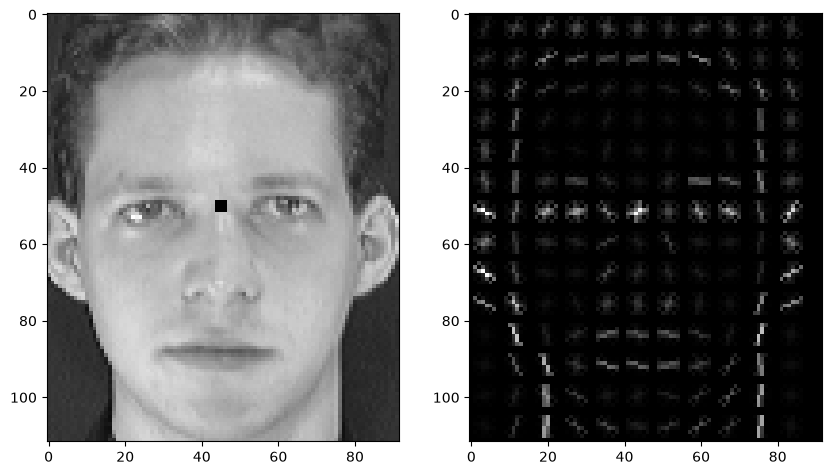

In [ ]:
plt.figure(figsize=(10,8))

plt.subplot(1,2,1)
plt.imshow(gray_image,cmap='gray')

plt.subplot(1,2,2)
plt.imshow(hog_image,cmap='gray')


In [421]:
# Compare your simplified HOG calculation with the library visualization. Explain why they may differ numerically.
new2=features[:36]

avg_diff=np.mean(new-new2)

print("Avg diff :",avg_diff)

Avg diff : -0.028913036695734733
